In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

DATA_PATH = Path("../data/processed/bloodmnist_preprocessed.npz")

with np.load(DATA_PATH) as data:
    X_train = data["X_train"]
    X_val = data["X_val"]
    X_test = data["X_test"]

    y_train = data["y_train"]
    y_val = data["y_val"]
    y_test = data["y_test"]

    class_names = data["class_names"]

# Flatten images for Random Forest
X_train_rf = X_train.reshape(X_train.shape[0], -1)
X_val_rf = X_val.reshape(X_val.shape[0], -1)
X_test_rf = X_test.reshape(X_test.shape[0], -1)

print("Data loaded successfully!")
print("Training shape:", X_train_rf.shape)

Data loaded successfully!
Training shape: (11943, 2352)


In [3]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_rf, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [4]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Vorhersagen für die Validierungsdaten
y_val_pred = rf_model.predict(X_val_rf)

# Accuracy
val_accuracy = accuracy_score(y_val, y_val_pred)

print(f"Validation Accuracy: {val_accuracy:.4f}")

# Detaillierter Bericht für jede Zellklasse
print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=class_names,
        digits=3
    )
)

Validation Accuracy: 0.8486

Classification Report:
                                                                     precision    recall  f1-score   support

                                                           basophil      0.840     0.516     0.640       122
                                                         eosinophil      0.905     0.945     0.925       311
                                                       erythroblast      0.962     0.813     0.881       155
immature granulocytes(myelocytes, metamyelocytes and promyelocytes)      0.652     0.776     0.709       290
                                                         lymphocyte      0.787     0.877     0.829       122
                                                           monocyte      0.830     0.580     0.683       143
                                                         neutrophil      0.882     0.961     0.920       333
                                                           platelet      0.

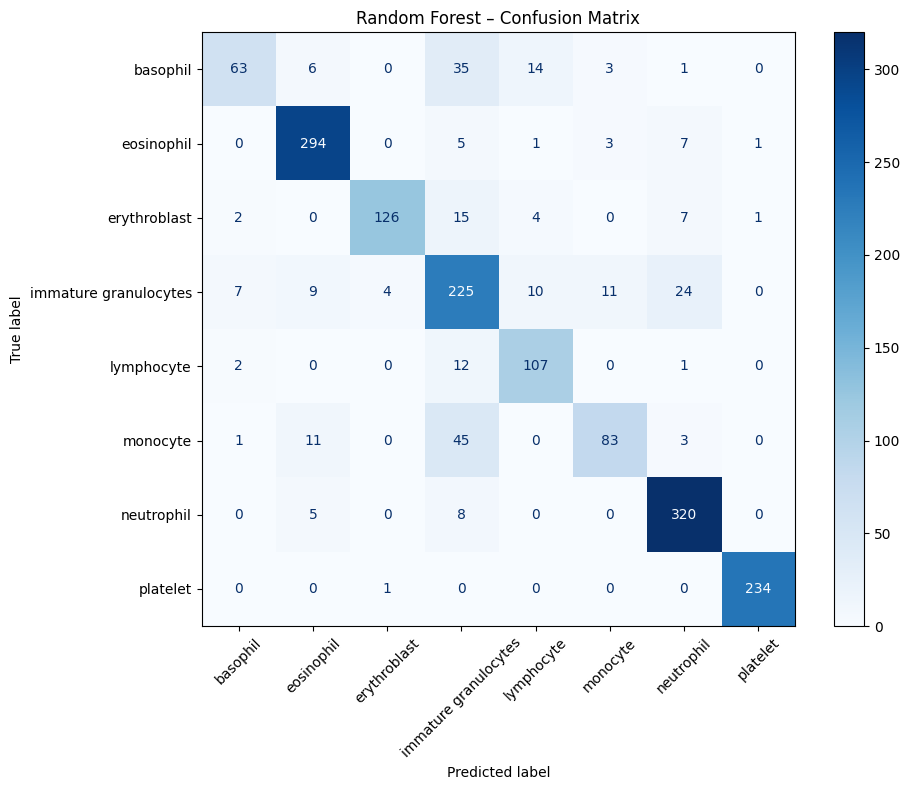

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay

display_names = [
    str(name).split("(")[0].strip()
    for name in class_names
]

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    display_labels=display_names,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax
)

plt.title("Random Forest – Confusion Matrix")
plt.tight_layout()
plt.show()

In [6]:
conf_matrix = np.array([
    [63,   6,   0,  35,  14,   3,   1,   0],
    [ 0, 294,   0,   5,   1,   3,   7,   1],
    [ 2,   0, 126,  15,   4,   0,   7,   1],
    [ 7,   9,   4, 225,  10,  11,  24,   0],
    [ 2,   0,   0,  12, 107,   0,   1,   0],
    [ 1,  11,   0,  45,   0,  83,   3,   0],
    [ 0,   5,   0,   8,   0,   0, 320,   0],
    [ 0,   0,   1,   0,   0,   0,   0, 234]
])

class_names = [
    "basophil", "eosinophil", "erythroblast", 
    "immature granulocytes", "lymphocyte", 
    "monocyte", "neutrophil", "platelet"
]

conf_matrix_normalized = (
    conf_matrix / conf_matrix.sum(axis=1, keepdims=True)
)

conf_matrix_normalized = conf_matrix_normalized * 100

print(np.round(conf_matrix_normalized, 1))

[[51.6  4.9  0.  28.7 11.5  2.5  0.8  0. ]
 [ 0.  94.5  0.   1.6  0.3  1.   2.3  0.3]
 [ 1.3  0.  81.3  9.7  2.6  0.   4.5  0.6]
 [ 2.4  3.1  1.4 77.6  3.4  3.8  8.3  0. ]
 [ 1.6  0.   0.   9.8 87.7  0.   0.8  0. ]
 [ 0.7  7.7  0.  31.5  0.  58.   2.1  0. ]
 [ 0.   1.5  0.   2.4  0.   0.  96.1  0. ]
 [ 0.   0.   0.4  0.   0.   0.   0.  99.6]]


In [7]:
# create a second Random Forest
rf_balanced_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

# train it
rf_balanced_model.fit(X_train_rf, y_train)

print("Balanced Random Forest training completed!")

y_val_pred_balanced = rf_balanced_model.predict(X_val_rf)

# classification report
print(
    classification_report(
        y_val,
        y_val_pred_balanced,
        target_names=class_names,
        digits=3
    )
)

Balanced Random Forest training completed!
                       precision    recall  f1-score   support

             basophil      0.795     0.475     0.595       122
           eosinophil      0.914     0.926     0.920       311
         erythroblast      0.941     0.826     0.880       155
immature granulocytes      0.622     0.755     0.682       290
           lymphocyte      0.782     0.852     0.816       122
             monocyte      0.842     0.594     0.697       143
           neutrophil      0.874     0.955     0.912       333
             platelet      0.987     0.996     0.992       235

             accuracy                          0.838      1711
            macro avg      0.845     0.797     0.812      1711
         weighted avg      0.845     0.838     0.835      1711



In [8]:
# Random Forest with more features considered
rf_features_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    max_features=0.1
)

rf_features_model.fit(X_train_rf, y_train)

print("Random Forest training completed!")

y_val_pred_features = rf_features_model.predict(X_val_rf)

print(
    classification_report(
        y_val,
        y_val_pred_features,
        target_names=class_names,
        digits=3
    )
)

Random Forest training completed!
                       precision    recall  f1-score   support

             basophil      0.831     0.484     0.611       122
           eosinophil      0.886     0.945     0.914       311
         erythroblast      0.936     0.845     0.888       155
immature granulocytes      0.645     0.759     0.697       290
           lymphocyte      0.774     0.844     0.808       122
             monocyte      0.798     0.580     0.672       143
           neutrophil      0.895     0.952     0.923       333
             platelet      0.987     0.991     0.989       235

             accuracy                          0.842      1711
            macro avg      0.844     0.800     0.813      1711
         weighted avg      0.846     0.842     0.838      1711



In [9]:
models = {
    "Baseline RF": rf_model,
    "Balanced RF": rf_balanced_model,
    "More Features RF": rf_features_model
}

for name, model in models.items():

    # Accuracy auf den Trainingsdaten
    train_accuracy = model.score(X_train_rf, y_train)

    # Accuracy auf den Validierungsdaten
    val_accuracy = model.score(X_val_rf, y_val)

    print(f"\n{name}")
    print(f"Training Accuracy:   {train_accuracy:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Difference:          {train_accuracy - val_accuracy:.4f}")


Baseline RF
Training Accuracy:   1.0000
Validation Accuracy: 0.8486
Difference:          0.1514

Balanced RF
Training Accuracy:   1.0000
Validation Accuracy: 0.8381
Difference:          0.1619

More Features RF
Training Accuracy:   1.0000
Validation Accuracy: 0.8416
Difference:          0.1584


In [10]:
rf_regularized_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=5
)

rf_regularized_model.fit(X_train_rf, y_train)

print("Regularized Random Forest training completed!")

y_val_pred_regularized = rf_regularized_model.predict(X_val_rf)

print(
    classification_report(
        y_val,
        y_val_pred_regularized,
        target_names=class_names,
        digits=3
    )
)

train_accuracy = rf_regularized_model.score(X_train_rf, y_train)
val_accuracy = rf_regularized_model.score(X_val_rf, y_val)

print(f"\nTraining Accuracy:   {train_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")

Regularized Random Forest training completed!
                       precision    recall  f1-score   support

             basophil      0.806     0.475     0.598       122
           eosinophil      0.896     0.939     0.917       311
         erythroblast      0.955     0.819     0.882       155
immature granulocytes      0.630     0.769     0.693       290
           lymphocyte      0.774     0.844     0.808       122
             monocyte      0.828     0.573     0.678       143
           neutrophil      0.885     0.952     0.918       333
             platelet      0.992     0.996     0.994       235

             accuracy                          0.839      1711
            macro avg      0.846     0.796     0.811      1711
         weighted avg      0.846     0.839     0.836      1711


Training Accuracy:   0.9807
Validation Accuracy: 0.8393


In [11]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    rf_model,
    MODEL_DIR / "random_forest_baseline.joblib"
)

print("Random Forest saved successfully!")

Random Forest saved successfully!
